Уровень 1

In [8]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"C:\Users\mrmik\Downloads\titanic")
train_path = BASE_DIR / "train.csv"

# Защитная проверка — если путь снова "поедет", увидим понятную ошибку
if not train_path.exists():
    raise FileNotFoundError(
        f"Файл не найден: {train_path}\n"
        f"Папка существует: {BASE_DIR.exists()}\n"
        f"Содержимое: {list(BASE_DIR.iterdir()) if BASE_DIR.exists() else 'папки нет'}"
    )

df = pd.read_csv(train_path)

# Диагностика — обязательный шаг перед расчётами
print(f"Строк: {len(df)}, колонок: {len(df.columns)}")
print(f"Колонки: {list(df.columns)}")
print(f"Пропуски в Age: {df['Age'].isna().sum()}")

# --- Задача 1: процент детей (младше 18 лет) ---
# Age содержит NaN (~177 из 891). NaN < 18 даёт False,
# поэтому считаем долю от пассажиров с известным возрастом
# и отдельно показываем, сколько данных "теряем".
known_age = df[df['Age'].notna()]
children_known = (known_age['Age'] < 18).sum()
children_pct = children_known / len(known_age) * 100
children_pct_all = (df['Age'] < 18).sum() / len(df) * 100

print(f"\n--- Дети (< 18 лет) ---")
print(f"Пассажиров с известным возрастом: {len(known_age)} из {len(df)}")
print(f"Детей: {children_known}")
print(f"Процент детей (от известных возрастов): {children_pct:.2f}%")
print(f"Процент детей (от всех пассажиров): {children_pct_all:.2f}%")

# --- Задача 2: соотношение мужчин/женщин ---
sex_counts = df['Sex'].value_counts()
males = sex_counts.get('male', 0)
females = sex_counts.get('female', 0)

print(f"\n--- Пол ---")
print(sex_counts)
print(f"Мужчины: {males} ({males / len(df) * 100:.2f}%)")
print(f"Женщины: {females} ({females / len(df) * 100:.2f}%)")
print(f"Соотношение M:F = {males / females:.3f} : 1")

Строк: 891, колонок: 12
Колонки: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Пропуски в Age: 177

--- Дети (< 18 лет) ---
Пассажиров с известным возрастом: 714 из 891
Детей: 113
Процент детей (от известных возрастов): 15.83%
Процент детей (от всех пассажиров): 12.68%

--- Пол ---
Sex
male      577
female    314
Name: count, dtype: int64
Мужчины: 577 (64.76%)
Женщины: 314 (35.24%)
Соотношение M:F = 1.838 : 1


Уровень 2

ЗАДАЧА 1. Пропуски в Sex / Age
Всего пассажиров:                 891
Нет пола (Sex):                   0 (0.00%)
Нет возраста (Age):               177 (19.87%)
Нет пола ИЛИ возраста:            177 (19.87%)
Нет пола И возраста одновременно: 0
Полная информация (Sex + Age):    714 (80.13%)
ЗАДАЧА 2. Гистограмма возраста
Строится по 714 пассажирам (исключено 177 с NaN)
Мин: 0.4, макс: 80.0, медиана: 28.0, среднее: 29.7


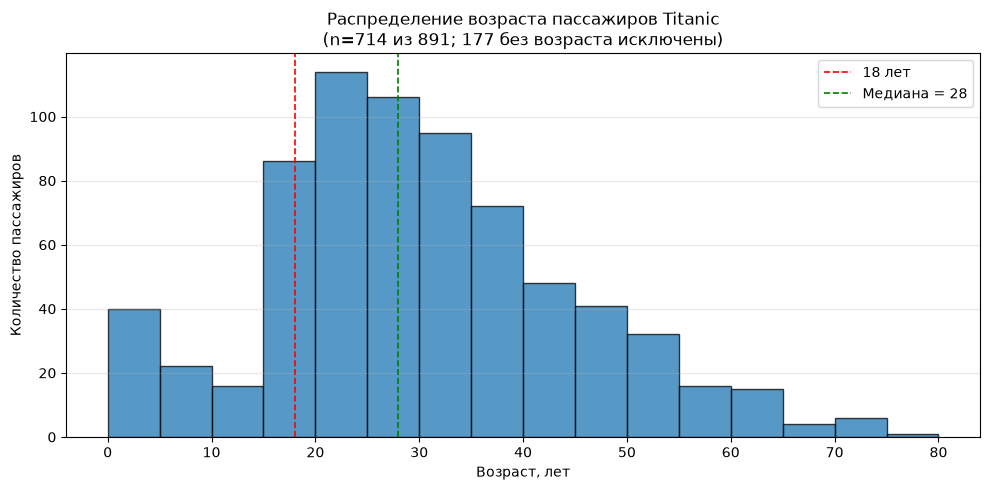

ЗАДАЧА 3. Выживаемость

 По полу
 female: 233 из 314 = 74.20%
   male: 109 из 577 = 18.89%

 Дети (< 18 лет, только с известным возрастом)
Детей всего:  113
Выжило детей: 61 (53.98%)
Взрослых:     601
Выжило взр.:  229 (38.10%)

 Дети в разрезе пола
 female:  38 из  55 = 69.09%
   male:  23 из  58 = 39.66%


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path(r"C:\Users\mrmik\Downloads\titanic")
df = pd.read_csv(BASE_DIR / "train.csv")

# Задача 1. Пропуски по полу и возрасту

print("ЗАДАЧА 1. Пропуски в Sex / Age")

n_total = len(df)
miss_sex = df['Sex'].isna().sum()
miss_age = df['Age'].isna().sum()
miss_either = (df['Sex'].isna() | df['Age'].isna()).sum()
miss_both = (df['Sex'].isna() & df['Age'].isna()).sum()

print(f"Всего пассажиров:                 {n_total}")
print(f"Нет пола (Sex):                   {miss_sex} ({miss_sex / n_total:.2%})")
print(f"Нет возраста (Age):               {miss_age} ({miss_age / n_total:.2%})")
print(f"Нет пола ИЛИ возраста:            {miss_either} ({miss_either / n_total:.2%})")
print(f"Нет пола И возраста одновременно: {miss_both}")

complete = df[df['Sex'].notna() & df['Age'].notna()]
print(f"Полная информация (Sex + Age):    {len(complete)} ({len(complete) / n_total:.2%})")

# Задача 2. Гистограмма по возрасту

print("ЗАДАЧА 2. Гистограмма возраста")

ages = df['Age'].dropna()
print(f"Строится по {len(ages)} пассажирам (исключено {df['Age'].isna().sum()} с NaN)")
print(f"Мин: {ages.min():.1f}, макс: {ages.max():.1f}, медиана: {ages.median():.1f}, среднее: {ages.mean():.1f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(ages, bins=range(0, 85, 5), edgecolor='black', alpha=0.75)
ax.set_title(f"Распределение возраста пассажиров Titanic\n"
             f"(n={len(ages)} из {n_total}; {df['Age'].isna().sum()} без возраста исключены)")
ax.set_xlabel("Возраст, лет")
ax.set_ylabel("Количество пассажиров")
ax.axvline(18, color='red', linestyle='--', linewidth=1.2, label='18 лет')
ax.axvline(ages.median(), color='green', linestyle='--', linewidth=1.2,
           label=f'Медиана = {ages.median():.0f}')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Задача 3. Процент выживших по полу и по детям

print("ЗАДАЧА 3. Выживаемость")

# по полу
print("\n По полу")
surv_by_sex = df.groupby('Sex')['Survived'].agg(['count', 'sum', 'mean'])
surv_by_sex.columns = ['всего', 'выжило', 'доля']
for sex, row in surv_by_sex.iterrows():
    print(f"{sex:>7}: {int(row['выжило']):>3} из {int(row['всего']):>3} = {row['доля']:.2%}")

# дети (младше 18)
# Для детей считаем выживаемость только по тем, у кого возраст известен —
# иначе получим смещение (NaN < 18 = False).
print("\n Дети (< 18 лет, только с известным возрастом)")
known = df[df['Age'].notna()]
children = known[known['Age'] < 18]
adults = known[known['Age'] >= 18]

print(f"Детей всего:  {len(children)}")
print(f"Выжило детей: {children['Survived'].sum()} "
      f"({children['Survived'].mean():.2%})")
print(f"Взрослых:     {len(adults)}")
print(f"Выжило взр.:  {adults['Survived'].sum()} "
      f"({adults['Survived'].mean():.2%})")

# дети по полу
print("\n Дети в разрезе пола")
child_sex = children.groupby('Sex')['Survived'].agg(['count', 'sum', 'mean'])
child_sex.columns = ['всего', 'выжило', 'доля']
for sex, row in child_sex.iterrows():
    print(f"{sex:>7}: {int(row['выжило']):>3} из {int(row['всего']):>3} = {row['доля']:.2%}")

Уровень 3

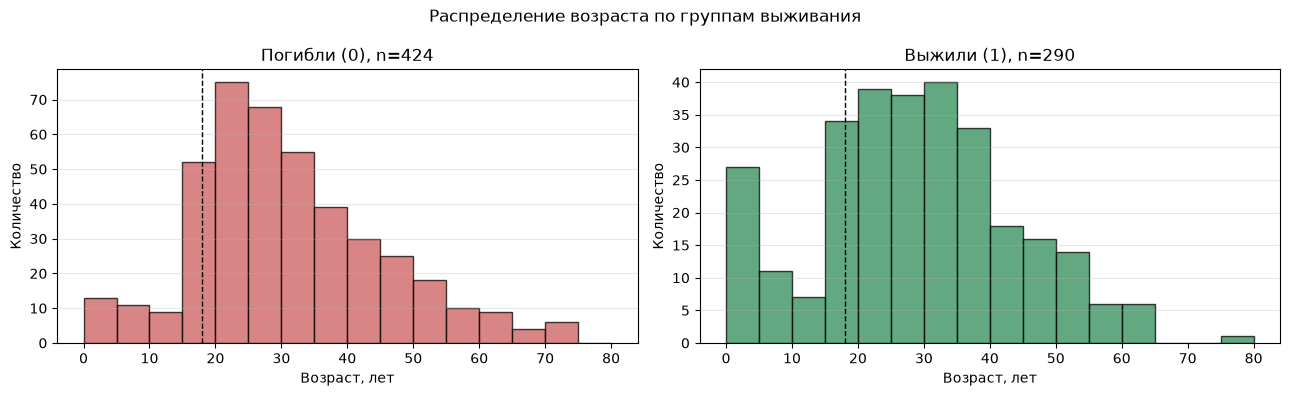

                   n  survived_rate
AgeGroup Sex                       
0-5      female   21          0.762
         male     23          0.652
5-12     female   11          0.273
         male     14          0.429
12-18    female   36          0.750
         male     34          0.088
18-30    female   90          0.756
         male    180          0.156
30-50    female   86          0.779
         male    155          0.226
50+      female   17          0.941
         male     47          0.128

Медианы возраста по (Sex, Pclass):
Sex     Pclass
female  1         35.0
        2         28.0
        3         21.5
male    1         40.0
        2         30.0
        3         25.0
Name: Age, dtype: float64
           v1: только пол: accuracy = 0.7868 (78.68%)
      v2: пол + возраст<6: accuracy = 0.7946 (79.46%)

Ошибок v2: 183
  женщин погибло: 81
  мужчин выжило:  94

Выживаемость по классу и полу:
               count   mean
Pclass Sex                 
1      female     94  0.968

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import accuracy_score

BASE_DIR = Path(r"C:\Users\mrmik\Downloads\titanic")
train = pd.read_csv(BASE_DIR / "train.csv")
test = pd.read_csv(BASE_DIR / "test.csv")

# 1. Анализ возраста: распределения по группам выживания
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, survived in zip(axes, [0, 1]):
    subset = train[train['Survived'] == survived]['Age'].dropna()
    ax.hist(subset, bins=range(0, 85, 5), edgecolor='black', alpha=0.75,
            color='indianred' if survived == 0 else 'seagreen')
    label = 'Погибли (0)' if survived == 0 else 'Выжили (1)'
    ax.set_title(f"{label}, n={len(subset)}")
    ax.set_xlabel("Возраст, лет")
    ax.set_ylabel("Количество")
    ax.axvline(18, color='black', linestyle='--', linewidth=1)
    ax.grid(axis='y', alpha=0.3)
plt.suptitle("Распределение возраста по группам выживания")
plt.tight_layout()
plt.show()

# Сводка: выживаемость по возрастным группам и полу
bins = [0, 5, 12, 18, 30, 50, 100]
labels = ['0-5', '5-12', '12-18', '18-30', '30-50', '50+']
train['AgeGroup'] = pd.cut(train['Age'], bins=bins, labels=labels)
summary = train.groupby(['AgeGroup', 'Sex'], observed=True)['Survived'].agg(['count', 'mean'])
summary.columns = ['n', 'survived_rate']
print(summary.round(3))

# 2. Обработка пропусков Age: медиана по (Sex, Pclass) из train
age_median = train.groupby(['Sex', 'Pclass'])['Age'].median()
print("\nМедианы возраста по (Sex, Pclass):")
print(age_median.round(1))

def impute_age(df):
    df = df.copy()
    mask = df['Age'].isna()
    df.loc[mask, 'Age'] = df[mask].apply(
        lambda r: age_median.loc[(r['Sex'], r['Pclass'])], axis=1
    )
    return df

train_i = impute_age(train)
test_i  = impute_age(test)

# 3. Модели: v1 (только пол) и v2 (пол + возраст)
def predict_sex(df):
    return (df['Sex'] == 'female').astype(int)

def predict_sex_age(df, child_age=6):
    return ((df['Sex'] == 'female') |
            ((df['Sex'] == 'male') & (df['Age'] < child_age))).astype(int)

for name, pred_fn in [("v1: только пол", predict_sex),
                      ("v2: пол + возраст<6", predict_sex_age)]:
    pred = pred_fn(train_i)
    acc = accuracy_score(train['Survived'], pred)
    print(f"{name:>25}: accuracy = {acc:.4f} ({acc:.2%})")

# Разбор ошибок v2
pred_v2 = predict_sex_age(train_i)
errors = train_i[train_i['Survived'] != pred_v2]
print(f"\nОшибок v2: {len(errors)}")
print(f"  женщин погибло: {((errors['Sex']=='female') & (errors['Survived']==0)).sum()}")
print(f"  мужчин выжило:  {((errors['Sex']=='male') & (errors['Survived']==1)).sum()}")

# 4. Дополнительные закономерности (Pclass, Title)
print("\nВыживаемость по классу и полу:")
print(train.groupby(['Pclass', 'Sex'])['Survived'].agg(['count', 'mean']).round(3))

train['Title'] = train['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
print("\nВыживаемость по Title:")
print(train.groupby('Title')['Survived']
      .agg(['count', 'mean'])
      .sort_values('count', ascending=False)
      .head(10).round(3))

# 5. Submission v2: предсказание на test.csv
test_pred = predict_sex_age(test_i)

submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': test_pred
})
submission_path = BASE_DIR / "submission_v2.csv"
submission.to_csv(submission_path, index=False)

print(f"\nСохранено: {submission_path}")
print(f"Строк: {len(submission)}")
print(f"Выживших: {submission['Survived'].sum()} ({submission['Survived'].mean():.2%})")

# Сравнение с gender-baseline
baseline = pd.read_csv(BASE_DIR / "gender_submission.csv")
diff = (baseline['Survived'] != submission['Survived']).sum()
print(f"Отличий от gender-baseline: {diff} из {len(submission)}")

# Проверка формата
assert len(submission) == 418
assert list(submission.columns) == ['PassengerId', 'Survived']
assert submission['Survived'].isin([0, 1]).all()
print("\n Формат корректен")